# Optical Imaging: PSF, OTF, Coherent vs. Incoherent

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-11-2D.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## 2D PSF and OTF profiles
Uses jinc.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch

# ==========================================
# 0. Formatting / Style Setup
# ==========================================
plot_params = {
    'font.size': 14,
    'font.family': 'sans-serif',
    'mathtext.fontset': 'stix',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
    'figure.figsize': (16, 12) # Taller figure for this layout
}
plt.rcParams.update(plot_params)

def apply_tick_style(ax):
    """Helper to apply strict tick styling."""
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

In [3]:
# ==========================================
# 1. Define Domain and Input Object
# ==========================================
N = 1024           # Number of points (Reduced for 2D efficiency)
X_max = 20.0       # Spatial extent
dx = X_max / N     # Spatial resolution

x = np.linspace(-X_max/2, X_max/2, N)
# 2D Grid
y = np.linspace(-X_max/2, X_max/2, N)
X, Y = np.meshgrid(x, y)

# Frequency domain setup
freqs = np.fft.fftfreq(N, d=dx)
FX, FY = np.meshgrid(np.fft.fftshift(freqs), np.fft.fftshift(freqs))

# Define Input Object O(x,y): Two narrow vertical bars
def object_func_2d(xx, yy):
    # Two 0.5-wide pulses separated by a 0.5 gap, infinite in Y (or bounded)
    # Let's make them bounded in Y to look like a resolution target
    t = xx
    pulse1 = np.where((t >= -0.75) & (t <= -0.25), 1.0, 0.0)
    pulse2 = np.where((t >= 0.25) & (t <= 0.75), 1.0, 0.0)
    
    # Bound in Y for better visualization
    y_mask = np.where((yy >= -2.0) & (yy <= 2.0), 1.0, 0.0)
    
    return (pulse1 + pulse2) * y_mask

O_2d = object_func_2d(X, Y)
# Spectrum of Object O(fx, fy)
O_f_2d = np.fft.fftshift(np.fft.fft2(O_2d) * (dx*dx))


In [4]:
# ==========================================
# 2. Coherent System Definition (2D)
# ==========================================
# The Pupil Function P(x,y) is a Circular Aperture
R = 0.5 # Radius (Diameter 1.0)
Pupil_2d = np.where(X**2 + Y**2 <= R**2, 1.0, 0.0)

# Coherent OTF (Pupil in freq domain coordinates)
# For simplicity in this demo, we treat Pupil as the transfer function directly.
H_coh_2d = Pupil_2d

# Coherent PSF h_coh(x,y) = IFFT(Pupil)
h_coh_2d_complex = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(Pupil_2d))) / (dx*dx)
# Normalize peak for visualization (optional, but keep physics consistent)
h_coh_2d_complex /= np.max(np.abs(h_coh_2d_complex))


In [5]:
# ==========================================
# 3. Incoherent System Definition (2D)
# ==========================================
# Incoherent PSF is intensity of Coherent PSF
h_inc_2d = np.abs(h_coh_2d_complex)**2

# Normalize volume to 1
h_inc_2d /= np.sum(h_inc_2d * dx * dx)

# Incoherent OTF is FFT of Incoherent PSF
H_inc_2d_complex = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(h_inc_2d))) * (dx*dx)
# Normalize DC to 1
H_inc_2d = H_inc_2d_complex / np.max(np.abs(H_inc_2d_complex))


In [6]:
# ==========================================
# 4. Perform Imaging (2D)
# ==========================================

# --- Coherent Imaging ---
# G_coh(f) = O(f) * P(f)
Img_coh_f = O_f_2d * Pupil_2d
# Img_coh_amp = np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(Img_coh_f))) / (dx*dx)
Img_coh_amp = np.fft.ifft2(np.fft.ifftshift(Img_coh_f)) / (dx*dx)
# Img_coh_int = np.abs(Img_coh_amp)**2
Img_coh_int = np.abs(Img_coh_amp)

# --- Incoherent Imaging ---
# G_inc(f) = O_intensity(f) * OTF_inc(f) ... wait, standard is Linear in Intensity
# I_inc = I_obj * h_inc (convolution)
# Let's do it via Frequency domain for speed
O_int_2d = np.abs(O_2d)**2 # Object is incoherent source intensity
O_int_f = np.fft.fftshift(np.fft.fft2(O_int_2d) * (dx*dx))

Img_inc_f = O_int_f * H_inc_2d
# Img_inc_int = np.real(np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(Img_inc_f))) / (dx*dx))
Img_inc_int = np.abs(np.fft.ifft2(np.fft.ifftshift(Img_inc_f)) / (dx*dx))


## Coherent only

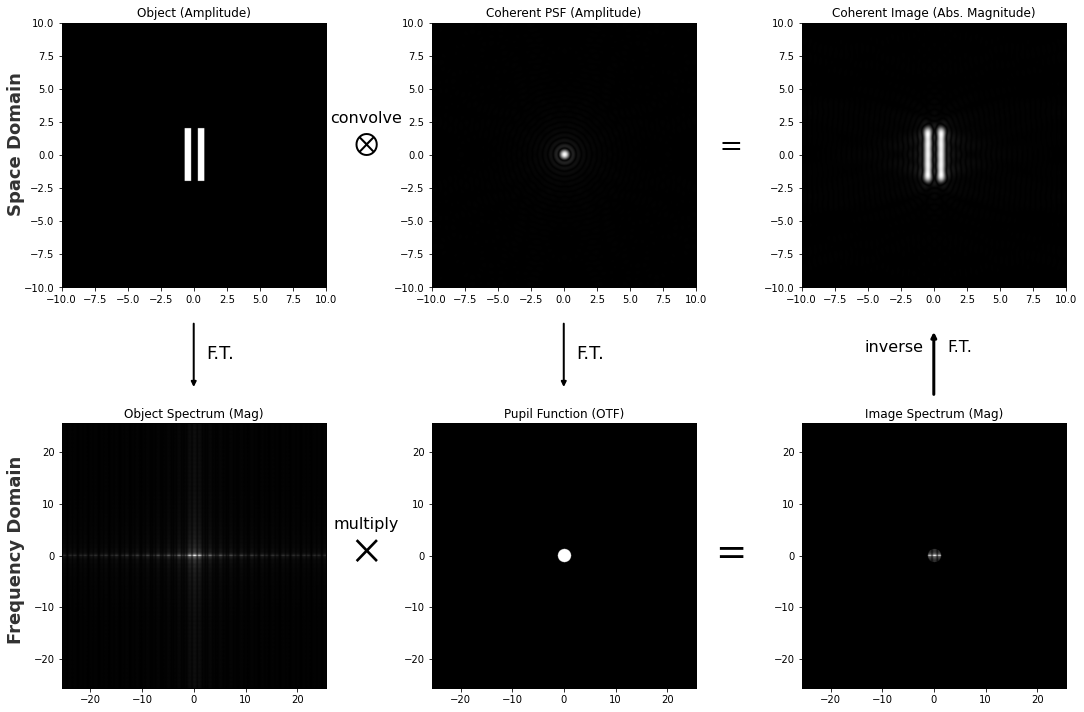

In [37]:
# Plot Coherent System (2D)
fig1, axes1 = plt.subplots(2, 3, figsize=(18, 12))
plt.subplots_adjust(wspace=0.4, hspace=0.2, top=0.90, bottom=0.05)

ext = [-X_max/2, X_max/2, -X_max/2, X_max/2]
f_ext = [FX.min(), FX.max(), FY.min(), FY.max()]

# Row 1: Spatial Domain
ax11 = axes1[0, 0]; ax11.set_title('Object (Amplitude)')
im1 = ax11.imshow(O_2d, extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im1, ax=ax11, fraction=0.046)

ax12 = axes1[0, 1]; ax12.set_title('Coherent PSF (Amplitude)')
im2 = ax12.imshow(np.abs(h_coh_2d_complex), extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im2, ax=ax12, fraction=0.046)

ax13 = axes1[0, 2]; ax13.set_title('Coherent Image (Abs. Magnitude)')
im3 = ax13.imshow(Img_coh_int, extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im3, ax=ax13, fraction=0.046)

# Row 2: Frequency Domain
gamma1 = 0.5
ax14 = axes1[1, 0]; ax14.set_title('Object Spectrum (Mag)')
# im4 = ax4.imshow(np.log10(np.abs(O_f_2d)+1e-12), extent=f_ext, cmap='gray', origin='lower')
im4 = ax14.imshow(np.abs(O_f_2d)**gamma1, extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im4, ax=ax14, fraction=0.046)

ax15 = axes1[1, 1]; ax15.set_title('Pupil Function (OTF)')
im5 = ax15.imshow(Pupil_2d, extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im5, ax=ax15, fraction=0.046)

ax16 = axes1[1, 2]; ax16.set_title('Image Spectrum (Mag)')
# im6 = ax6.imshow(np.log10(np.abs(Img_coh_f)+1e-12), extent=f_ext, cmap='gray', origin='lower')
im6 = ax16.imshow(np.abs(Img_coh_f)**gamma1, extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im6, ax=ax16, fraction=0.046)

# --- Annotations ---
# We use figure coordinates for consistent placement across subplots
# Adjust coordinates slightly for 2D layout if needed.

# 1. Convolution / Multiplication Arrows (Horizontal)
# Row 1 (Space): Object * PSF = Image
fig1.text(0.36, 0.75, "convolve", fontsize=16, ha='center', va='center')
fig1.text(0.36, 0.72, r"$\otimes$", fontsize=30, ha='center', va='center', weight='bold')
fig1.text(0.64, 0.72, r"$=$", fontsize=30, ha='center', va='center', weight='bold')

# Row 2 (Freq): Object . OTF = Image
fig1.text(0.36, 0.28, "multiply", fontsize=16, ha='center', va='center')
fig1.text(0.36, 0.25, r"$\times$", fontsize=40, ha='center', va='center', weight='bold')
fig1.text(0.64, 0.25, r"$=$", fontsize=40, ha='center', va='center', weight='bold')

# 2. Fourier Transform Arrows (Vertical)
# Col 1: Object Space -> Object Freq
# We draw an arrow from bottom of ax1 to top of ax4
# Using ConnectionPatch is robust, but figure coordinates are easier for quick script
# Let's use simple text for F symbol and standard arrows if possible, 
# or just text labels as in the 1D file snippet provided?
# The snippet showed: draw_arrow_vertical(ax_obj_x, ax_obj_f, r"$\mathcal{F}$")

# We need to define the helper functions if they aren't in the cell
def draw_arrow_vertical(ax_top, ax_bottom, text):
    xyA = (0.5, -0.1) # Bottom center of top axes
    xyB = (0.5, 1.1) # Top center of bottom axes
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_top, axesB=ax_bottom,
                          arrowstyle="-|>", shrinkA=10, shrinkB=10, linewidth=2, color="black")
    ax_top.add_artist(con)
    # Add text in the middle
    # We can't easily get mid point in one coord system without transforms, 
    # but we can place text relative to one axes
    ax_top.text(0.6, -0.25, text, transform=ax_top.transAxes, ha='center', va='center', fontsize=18)

# Apply Vertical Arrows
draw_arrow_vertical(axes1[0,0], axes1[1,0], "F.T.")
draw_arrow_vertical(axes1[0,1], axes1[1,1], "F.T.")
# Inverse Transform Arrow (Upwards)
con_inv = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax16, axesB=ax13,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax16.add_artist(con_inv)
ax13.text(0.35, -0.2, "inverse", transform=ax13.transAxes, 
          ha='center', va='top', fontsize=16)
ax13.text(0.6, -0.2, "F.T.", transform=ax13.transAxes, 
          ha='center', va='top', fontsize=16)

# 3. Row Labels
fig1.text(0.09, 0.72, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig1.text(0.09, 0.25, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')

# plt.tight_layout()
plt.show()

### Plot 1D cross-sections

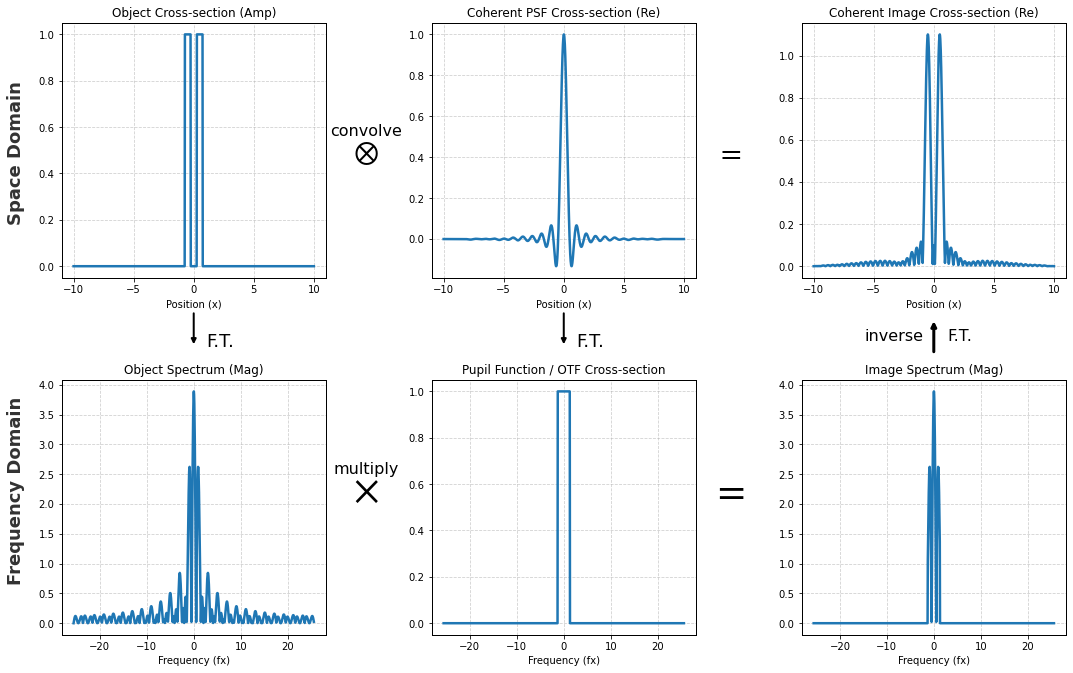

In [33]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Determine the center index for slicing
mid_idx = O_2d.shape[0] // 2

# 2. Create the 1D x-axes based on your existing 'extent' limits
# ext = [xmin, xmax, ymin, ymax]
x_axis = np.linspace(ext[0], ext[1], O_2d.shape[1])
f_axis = np.linspace(f_ext[0], f_ext[1], O_f_2d.shape[1])

# 3. Create the figure
fig2, axes2 = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(wspace=0.4, hspace=0.4, top=0.90, bottom=0.05)
# --- Row 1: Spatial Domain Cross-Sections ---

# Plot 1: Object
ax21 = axes2[0, 0]
ax21.set_title('Object Cross-section (Amp)')
ax21.plot(x_axis, O_2d[mid_idx, :])
ax21.set_xlabel('Position (x)')
ax21.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Coherent PSF
ax22 = axes2[0, 1]
ax22.set_title('Coherent PSF Cross-section (Re)')
ax22.plot(x_axis, np.real(h_coh_2d_complex)[mid_idx, :])
ax22.set_xlabel('Position (x)')
ax22.grid(True, linestyle='--', alpha=0.6)

# Plot 3: Coherent Image
ax23 = axes2[0, 2]
ax23.set_title('Coherent Image Cross-section (Re)')
ax23.plot(x_axis, np.real(Img_coh_int)[mid_idx, :])
ax23.set_xlabel('Position (x)')
ax23.grid(True, linestyle='--', alpha=0.6)

# --- Row 2: Frequency Domain Cross-Sections ---

# Plot 4: Object Spectrum
ax24 = axes2[1, 0]
ax24.set_title('Object Spectrum (Mag)')
# ax24.plot(f_axis, np.log10(np.abs(O_f_2d)[mid_idx, :] + 1e-12))
ax24.plot(f_axis, np.abs(O_f_2d)[mid_idx, :])
ax24.set_xlabel('Frequency (fx)')
ax24.grid(True, linestyle='--', alpha=0.6)

# Plot 5: Pupil Function (OTF)
ax25 = axes2[1, 1]
ax25.set_title('Pupil Function / OTF Cross-section')
ax25.plot(f_axis, Pupil_2d[mid_idx, :])
ax25.set_xlabel('Frequency (fx)')
ax25.grid(True, linestyle='--', alpha=0.6)

# Plot 6: Image Spectrum
ax26 = axes2[1, 2]
ax26.set_title('Image Spectrum (Mag)')
# ax26.plot(f_axis, np.log10(np.abs(Img_coh_f)[mid_idx, :] + 1e-12))
ax26.plot(f_axis, np.abs(Img_coh_f)[mid_idx, :])
ax26.set_xlabel('Frequency (fx)')
ax26.grid(True, linestyle='--', alpha=0.6)

# --- Annotations ---
# We use figure coordinates for consistent placement across subplots
# Adjust coordinates slightly for 2D layout if needed.

# 1. Convolution / Multiplication Arrows (Horizontal)
# Row 1 (Space): Object * PSF = Image
fig2.text(0.36, 0.75, "convolve", fontsize=16, ha='center', va='center')
fig2.text(0.36, 0.72, r"$\otimes$", fontsize=30, ha='center', va='center', weight='bold')
fig2.text(0.64, 0.72, r"$=$", fontsize=30, ha='center', va='center', weight='bold')

# Row 2 (Freq): Object . OTF = Image
fig2.text(0.36, 0.28, "multiply", fontsize=16, ha='center', va='center')
fig2.text(0.36, 0.25, r"$\times$", fontsize=40, ha='center', va='center', weight='bold')
fig2.text(0.64, 0.25, r"$=$", fontsize=40, ha='center', va='center', weight='bold')

# 2. Fourier Transform Arrows (Vertical)
# Col 1: Object Space -> Object Freq
# We draw an arrow from bottom of ax1 to top of ax4
# Using ConnectionPatch is robust, but figure coordinates are easier for quick script
# Let's use simple text for F symbol and standard arrows if possible, 
# or just text labels as in the 1D file snippet provided?
# The snippet showed: draw_arrow_vertical2(ax_obj_x, ax_obj_f, r"$\mathcal{F}$")

# We need to define the helper functions if they aren't in the cell
def draw_arrow_vertical2(ax_top, ax_bottom, text):
    xyA = (0.5, -0.1) # Bottom center of top axes
    xyB = (0.5, 1.1) # Top center of bottom axes
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_top, axesB=ax_bottom,
                          arrowstyle="-|>", shrinkA=10, shrinkB=10, linewidth=2, color="black")
    ax_top.add_artist(con)
    # Add text in the middle
    # We can't easily get mid point in one coord system without transforms, 
    # but we can place text relative to one axes
    ax_top.text(0.6, -0.25, text, transform=ax_top.transAxes, ha='center', va='center', fontsize=18)

# Apply Vertical Arrows
draw_arrow_vertical2(axes2[0,0], axes2[1,0], "F.T.")
draw_arrow_vertical2(axes2[0,1], axes2[1,1], "F.T.")
# Inverse Transform Arrow (Upwards)
con_inv2 = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax26, axesB=ax23,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax26.add_artist(con_inv2)
ax23.text(0.35, -0.2, "inverse", transform=ax23.transAxes, 
          ha='center', va='top', fontsize=16)
ax23.text(0.6, -0.2, "F.T.", transform=ax23.transAxes, 
          ha='center', va='top', fontsize=16)

# 3. Row Labels
fig2.text(0.09, 0.72, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig2.text(0.09, 0.25, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')

# plt.tight_layout()
plt.show()

## Incoherent case

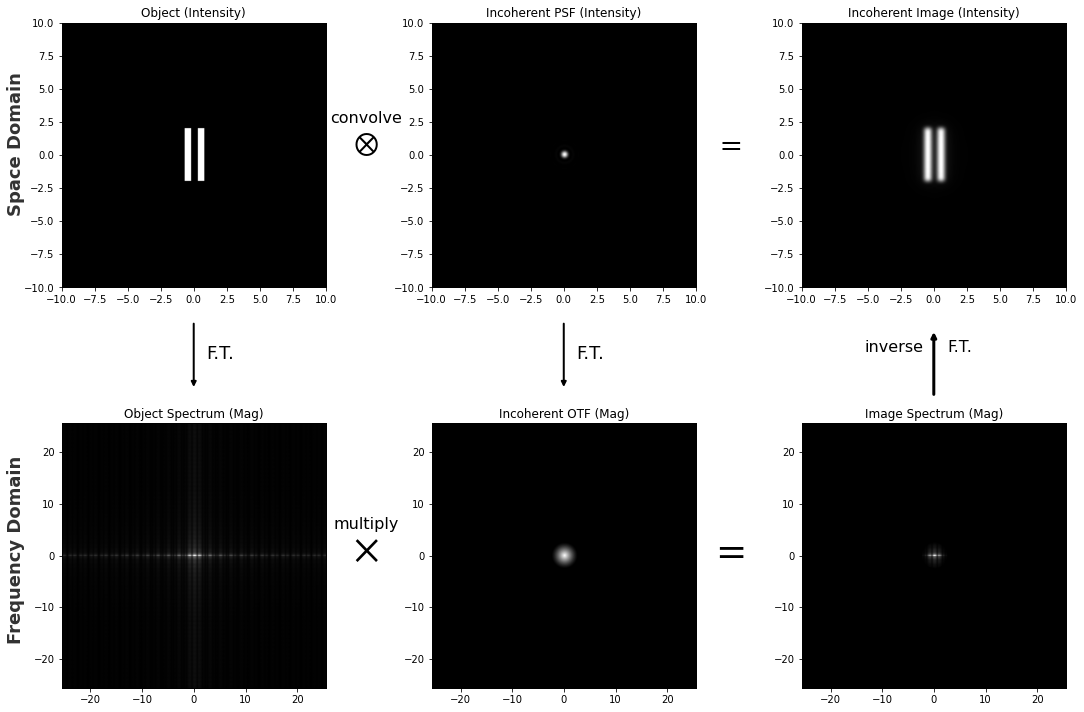

In [39]:
# Plot Incoherent System (2D)
fig3, axes3 = plt.subplots(2, 3, figsize=(18, 12))
plt.subplots_adjust(wspace=0.4, hspace=0.2, top=0.90, bottom=0.05)

# Row 1: Spatial Domain
ax31 = axes3[0, 0]; ax31.set_title('Object (Intensity)')
im31 = ax31.imshow(O_int_2d, extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im31, ax=ax31, fraction=0.046)

ax32 = axes3[0, 1]; ax32.set_title('Incoherent PSF (Intensity)')
im32 = ax32.imshow(h_inc_2d, extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im32, ax=ax32, fraction=0.046)

ax33 = axes3[0, 2]; ax33.set_title('Incoherent Image (Intensity)')
im33 = ax33.imshow(Img_inc_int, extent=ext, cmap='gray', origin='lower')
# plt.colorbar(im33, ax=ax33, fraction=0.046)

# Row 2: Frequency Domain
gamma2 = 0.5
ax34 = axes3[1, 0]; ax34.set_title('Object Spectrum (Mag)')
# im4 = ax4.imshow(np.log10(np.abs(O_int_f)+1e-12), extent=f_ext, cmap='gray', origin='lower')
im34 = ax34.imshow(np.abs(O_int_f)**gamma2, extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im34, ax=ax34, fraction=0.046)

ax35 = axes3[1, 1]; ax35.set_title('Incoherent OTF (Mag)')
im35 = ax35.imshow(np.abs(H_inc_2d), extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im35, ax=ax35, fraction=0.046)

ax36 = axes3[1, 2]; ax36.set_title('Image Spectrum (Mag)')
# im6 = ax6.imshow(np.log10(np.abs(Img_inc_f)+1e-12), extent=f_ext, cmap='gray', origin='lower')
im36 = ax36.imshow(np.abs(Img_inc_f)**gamma2, extent=f_ext, cmap='gray', origin='lower')
# plt.colorbar(im36, ax=ax36, fraction=0.046)

# --- Annotations ---
# We use figure coordinates for consistent placement across subplots
# Adjust coordinates slightly for 2D layout if needed.

# 1. Convolution / Multiplication Arrows (Horizontal)
# Row 1 (Space): Object * PSF = Image
fig3.text(0.36, 0.75, "convolve", fontsize=16, ha='center', va='center')
fig3.text(0.36, 0.72, r"$\otimes$", fontsize=30, ha='center', va='center', weight='bold')
fig3.text(0.64, 0.72, r"$=$", fontsize=30, ha='center', va='center', weight='bold')

# Row 2 (Freq): Object . OTF = Image
fig3.text(0.36, 0.28, "multiply", fontsize=16, ha='center', va='center')
fig3.text(0.36, 0.25, r"$\times$", fontsize=40, ha='center', va='center', weight='bold')
fig3.text(0.64, 0.25, r"$=$", fontsize=40, ha='center', va='center', weight='bold')

# 2. Fourier Transform Arrows (Vertical)
# Col 1: Object Space -> Object Freq
# We draw an arrow from bottom of ax1 to top of ax4
# Using ConnectionPatch is robust, but figure coordinates are easier for quick script
# Let's use simple text for F symbol and standard arrows if possible, 
# or just text labels as in the 1D file snippet provided?
# The snippet showed: draw_arrow_vertical3(ax_obj_x, ax_obj_f, r"$\mathcal{F}$")

# We need to define the helper functions if they aren't in the cell
def draw_arrow_vertical3(ax_top, ax_bottom, text):
    xyA = (0.5, -0.1) # Bottom center of top axes
    xyB = (0.5, 1.1) # Top center of bottom axes
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_top, axesB=ax_bottom,
                          arrowstyle="-|>", shrinkA=10, shrinkB=10, linewidth=2, color="black")
    ax_top.add_artist(con)
    # Add text in the middle
    # We can't easily get mid point in one coord system without transforms, 
    # but we can place text relative to one axes
    ax_top.text(0.6, -0.25, text, transform=ax_top.transAxes, ha='center', va='center', fontsize=18)

# Apply Vertical Arrows
draw_arrow_vertical3(axes3[0,0], axes3[1,0], "F.T.")
draw_arrow_vertical3(axes3[0,1], axes3[1,1], "F.T.")
# Inverse Transform Arrow (Upwards)
con_inv3 = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax36, axesB=ax33,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax36.add_artist(con_inv3)
ax33.text(0.35, -0.2, "inverse", transform=ax33.transAxes, 
          ha='center', va='top', fontsize=16)
ax33.text(0.6, -0.2, "F.T.", transform=ax33.transAxes, 
          ha='center', va='top', fontsize=16)

# 3. Row Labels
fig3.text(0.09, 0.72, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig3.text(0.09, 0.25, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')


# plt.tight_layout()
plt.show()

### 1D cross-sections

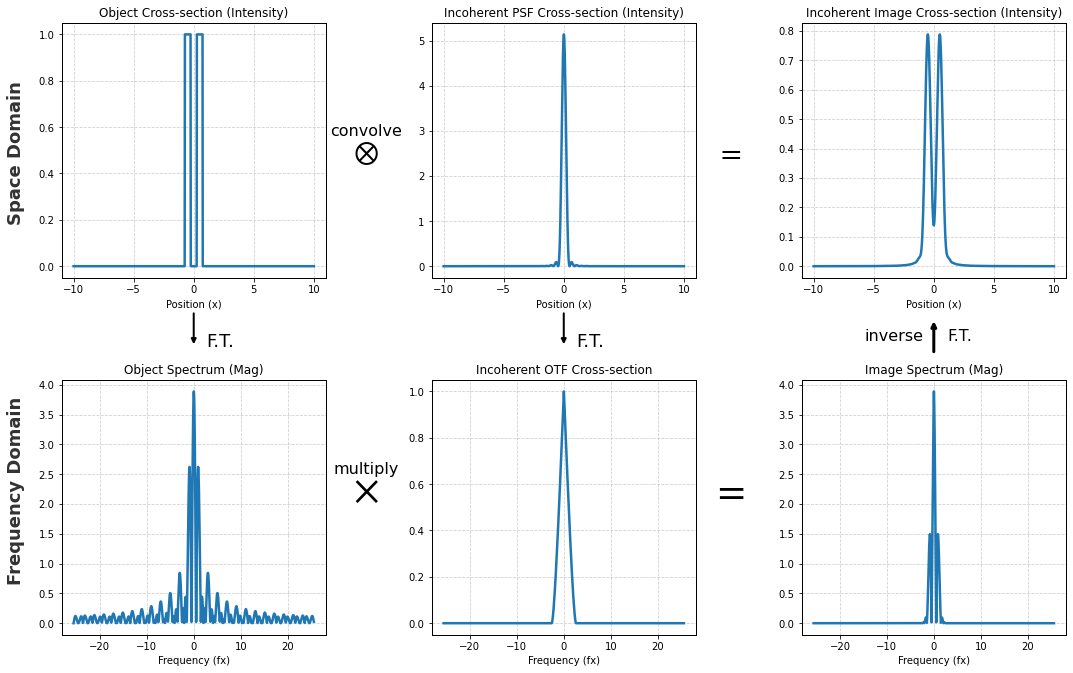

In [41]:
# 1. Determine the center index for slicing
mid_idx4 = O_int_2d.shape[0] // 2

# 2. Create the 1D x-axes based on your existing 'extent' limits
# ext = [xmin, xmax, ymin, ymax]
x_axis4 = np.linspace(ext[0], ext[1], O_int_2d.shape[1])
f_axis4 = np.linspace(f_ext[0], f_ext[1], O_int_f.shape[1])

# 3. Create the figure
fig4, axes4 = plt.subplots(2, 3, figsize=(18, 10))
plt.subplots_adjust(wspace=0.4, hspace=0.4, top=0.90, bottom=0.05)

# --- Row 1: Spatial Domain Cross-Sections ---

# Plot 1: Object Intensity
ax41 = axes4[0, 0]
ax41.set_title('Object Cross-section (Intensity)')
ax41.plot(x_axis4, O_int_2d[mid_idx4, :])
ax41.set_xlabel('Position (x)')
ax41.grid(True, linestyle='--', alpha=0.6)

# Plot 2: Incoherent PSF
ax42 = axes4[0, 1]
ax42.set_title('Incoherent PSF Cross-section (Intensity)')
ax42.plot(x_axis4, h_inc_2d[mid_idx4, :])
ax42.set_xlabel('Position (x)')
ax42.grid(True, linestyle='--', alpha=0.6)

# Plot 3: Incoherent Image
ax43 = axes4[0, 2]
ax43.set_title('Incoherent Image Cross-section (Intensity)')
ax43.plot(x_axis4, Img_inc_int[mid_idx4, :])
ax43.set_xlabel('Position (x)')
ax43.grid(True, linestyle='--', alpha=0.6)

# --- Row 2: Frequency Domain Cross-Sections ---

# Plot 4: Object Spectrum
ax44 = axes4[1, 0]
ax44.set_title('Object Spectrum (Mag)')
# ax44.plot(f_axis4, np.log10(np.abs(O_int_f)[mid_idx4, :] + 1e-12))
ax44.plot(f_axis4, np.abs(O_int_f)[mid_idx4, :])
ax44.set_xlabel('Frequency (fx)')
ax44.grid(True, linestyle='--', alpha=0.6)

# Plot 5: Incoherent OTF
ax45 = axes4[1, 1]
ax45.set_title('Incoherent OTF Cross-section')
# The Incoherent OTF is usually normalized to 1 at DC.
# It typically doesn't require log scaling to be visible.
ax45.plot(f_axis4, np.abs(H_inc_2d)[mid_idx4, :])
ax45.set_xlabel('Frequency (fx)')
ax45.grid(True, linestyle='--', alpha=0.6)

# Plot 6: Image Spectrum
ax46 = axes4[1, 2]
ax46.set_title('Image Spectrum (Mag)')
# ax46.plot(f_axis4, np.log10(np.abs(Img_inc_f)[mid_idx4, :] + 1e-12))
ax46.plot(f_axis4, np.abs(Img_inc_f)[mid_idx4, :])
ax46.set_xlabel('Frequency (fx)')
ax46.grid(True, linestyle='--', alpha=0.6)

# --- Annotations ---
# We use figure coordinates for consistent placement across subplots
# Adjust coordinates slightly for 2D layout if needed.

# 1. Convolution / Multiplication Arrows (Horizontal)
# Row 1 (Space): Object * PSF = Image
fig4.text(0.36, 0.75, "convolve", fontsize=16, ha='center', va='center')
fig4.text(0.36, 0.72, r"$\otimes$", fontsize=30, ha='center', va='center', weight='bold')
fig4.text(0.64, 0.72, r"$=$", fontsize=30, ha='center', va='center', weight='bold')

# Row 2 (Freq): Object . OTF = Image
fig4.text(0.36, 0.28, "multiply", fontsize=16, ha='center', va='center')
fig4.text(0.36, 0.25, r"$\times$", fontsize=40, ha='center', va='center', weight='bold')
fig4.text(0.64, 0.25, r"$=$", fontsize=40, ha='center', va='center', weight='bold')

# 2. Fourier Transform Arrows (Vertical)
# Col 1: Object Space -> Object Freq
# We draw an arrow from bottom of ax1 to top of ax4
# Using ConnectionPatch is robust, but figure coordinates are easier for quick script
# Let's use simple text for F symbol and standard arrows if possible, 
# or just text labels as in the 1D file snippet provided?
# The snippet showed: draw_arrow_vertical4(ax_obj_x, ax_obj_f, r"$\mathcal{F}$")

# We need to define the helper functions if they aren't in the cell
def draw_arrow_vertical4(ax_top, ax_bottom, text):
    xyA = (0.5, -0.1) # Bottom center of top axes
    xyB = (0.5, 1.1) # Top center of bottom axes
    con = ConnectionPatch(xyA=xyA, xyB=xyB, coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax_top, axesB=ax_bottom,
                          arrowstyle="-|>", shrinkA=10, shrinkB=10, linewidth=2, color="black")
    ax_top.add_artist(con)
    # Add text in the middle
    # We can't easily get mid point in one coord system without transforms, 
    # but we can place text relative to one axes
    ax_top.text(0.6, -0.25, text, transform=ax_top.transAxes, ha='center', va='center', fontsize=18)

# Apply Vertical Arrows
draw_arrow_vertical4(axes4[0,0], axes4[1,0], "F.T.")
draw_arrow_vertical4(axes4[0,1], axes4[1,1], "F.T.")
# Inverse Transform Arrow (Upwards)
con_inv4 = ConnectionPatch(xyA=(0.5, 1.11), xyB=(0.5, -0.15), 
                          coordsA="axes fraction", coordsB="axes fraction",
                          axesA=ax46, axesB=ax43,
                          arrowstyle="-|>", shrinkB=5, linewidth=3, color="black")
ax46.add_artist(con_inv4)
ax43.text(0.35, -0.2, "inverse", transform=ax43.transAxes, 
          ha='center', va='top', fontsize=16)
ax43.text(0.6, -0.2, "F.T.", transform=ax43.transAxes, 
          ha='center', va='top', fontsize=16)

# 3. Row Labels
fig4.text(0.09, 0.72, "Space Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')
fig4.text(0.09, 0.25, "Frequency Domain", rotation=90, va='center', ha='center', fontsize=18, weight='bold', color='#333')


# plt.tight_layout()
plt.show()